# 03 · An agent builds a world

A Strands agent gets two tools, `sim.tool` and `robot.tool`, and edits a MuJoCo world from plain English.
Every turn below is a real Claude call on Amazon Bedrock; the renders and tool calls are what that run did, and a
re-run gets different replies.

![a sentence becomes tool calls, the world rebuilds, the agent looks](media/03/turn.svg)

Needs `uv pip install -e ".[mujoco]" strands-agents` and Bedrock access: `AWS_BEARER_TOKEN_BEDROCK` (or AWS
credentials) plus a model id in `STRANDS_MODEL_ID`.

In [1]:
import io
import json
import os
import sys

import numpy as np
from PIL import Image
from strands import Agent

import _nb
from strands_robots import Robot, Simulation

MEDIA = _nb.MEDIA / "03"
MEDIA.mkdir(parents=True, exist_ok=True)
print("model:", os.environ["STRANDS_MODEL_ID"])

model: global.anthropic.claude-opus-5-5


One world, one SO-101, and a table: a fixed box 4 cm high in front of the arm.


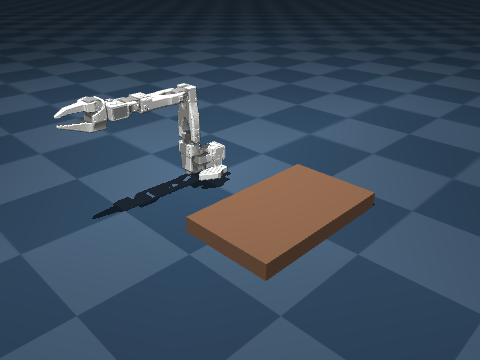

In [2]:
sim = Simulation()
arm = Robot("so101", sim=sim)
sim.add_object("table", shape="box", size=(0.12, 0.2, 0.02), position=(0.3, 0.0, 0.02), color=(0.55, 0.4, 0.3, 1), free=False)
sim.camera("hero", position=(0.85, -0.7, 0.55), target=(0.15, 0.0, 0.05), size=(480, 360))
_nb.show(_nb.image(sim.render("hero"), width=480))

Both tools are generated from the code: one `rpc` selector per tool, one argument object per rpc.

In [3]:
for tool in (sim.tool, arm.tool):
    rpcs = tool.tool_spec["inputSchema"]["json"]["properties"]["rpc"]["enum"]
    print(f"{tool.tool_name:12s} {rpcs}")
print(json.dumps(sim.tool.tool_spec["inputSchema"]["json"]["properties"]["add_object"]["properties"]["shape"]))

sim_world    ['add_robot', 'add_object', 'camera', 'contacts', 'control_step', 'describe', 'light', 'pose', 'randomize', 'remove', 'render', 'reset', 'run', 'set_pose', 'step']
robot_so101  ['describe', 'observe', 'act', 'run', 'stop', 'hold', 'estop']
{"type": ["string", "null"], "enum": ["box", "sphere", "cylinder", "capsule", null]}


The agent, with strands' default executor. It runs tool calls concurrently; a world still applies them in the
order the model sent them, so a turn that adds a camera and renders it works.

In [4]:
agent = Agent(
    model=os.environ["STRANDS_MODEL_ID"],
    tools=[sim.tool, arm.tool],
    callback_handler=None,
)


SEEN = set()  # tool-call ids already printed (strands trims old messages, so an index into agent.messages drifts)


def new_calls():
    """The tool calls not printed yet, one line each: rpc, its arguments, ok or the error the model read."""
    results = {
        b["toolResult"]["toolUseId"]: b["toolResult"]
        for m in agent.messages for b in m["content"] if "toolResult" in b
    }
    for m in agent.messages:
        for b in m["content"]:
            if "toolUse" in b and b["toolUse"]["toolUseId"] not in SEEN:
                use = b["toolUse"]
                SEEN.add(use["toolUseId"])
                rpc = use["input"].get("rpc")
                res = results.get(use["toolUseId"], {})
                note = "ok" if res.get("status") == "success" else res.get("content", [{}])[0].get("text", "")[:120]
                print(f"  {use['name']}.{rpc}({json.dumps(use['input'].get(rpc) or {})})  -> {note}")


def turn(ask, name):
    """One request: render before, the agent's turn, the calls it made, render after (saved to media/03)."""
    before = sim.render("hero")
    reply = agent(ask)
    after = sim.render("hero")
    print(f"> {ask}\n")
    new_calls()
    print(f"\n{str(reply).strip()}")
    pair = np.concatenate([before, np.full((before.shape[0], 8, 3), 255, np.uint8), after], axis=1)
    Image.fromarray(pair).save(MEDIA / f"{name}.png")
    _nb.show(_nb.image(pair, width=720))

## Turn 1: a red cube on the table

Before on the left, after on the right (the fixed `hero` camera).

> add a red cube on the table

  sim_world.describe({})  -> ok
  sim_world.add_object({"name": "red_cube", "shape": "box", "size": [0.02, 0.02, 0.02], "color": [1, 0, 0, 1], "position": [0.3, 0.0, 0.1], "mass": 0.05})  -> ok
  sim_world.step({"n": 300})  -> ok
  sim_world.pose({"body": "red_cube"})  -> ok
  sim_world.render({})  -> ok

I added a red cube named `red_cube` to the table, and the render shows it there.

- **Size and mass:** it's 4 cm on each side and weighs 50 g.
- **Position:** it's at the center of the table, (0.30, 0.00) m. I dropped it from slightly above and stepped the simulation until it settled. Its center is now at about 0.06 m height, so the table top is at about 0.04 m.

It's about 30 cm in front of the arm's base. The arm currently points away from the table, so it would need to swing over before it can pick the cube up.



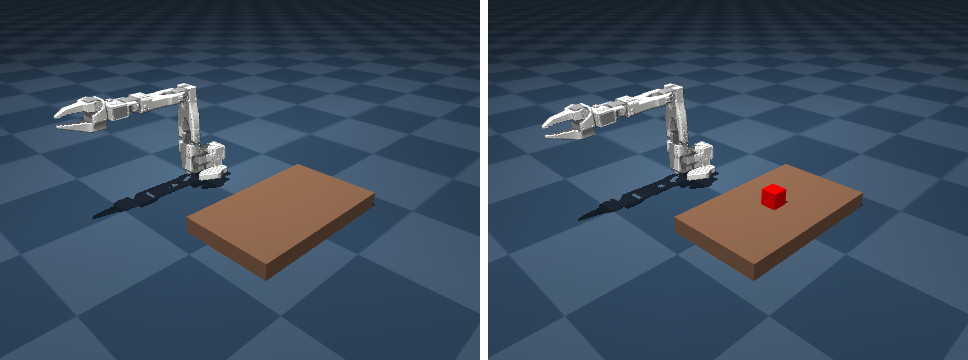

In [5]:
turn("add a red cube on the table", "t1_red_cube")

The tool says `size` is a half-extent in metres (a radius for a sphere), so the side the reply gives is twice the
`size` in the call.

## Turn 2: a blue ball and a light

`light` adds a spot (or, with `directional=True`, a sun); the same name again moves or recolors it.

> add a blue ball and a light

  sim_world.add_object({"color": [0, 0.3, 1, 1], "mass": 0.03, "name": "blue_ball", "position": [0.3, 0.08, 0.1], "shape": "sphere", "size": 0.02})  -> ok
  sim_world.light({"name": "key_light", "position": [0.3, 0, 1.2], "direction": [0, 0, -1]})  -> ok
  sim_world.step({"n": 300})  -> ok
  sim_world.pose({"body": "blue_ball"})  -> ok
  sim_world.render({})  -> ok

I added a blue ball (`blue_ball`) on the table and a light (`key_light`) above the scene, and the render shows both.

- **Blue ball:** it's 4 cm across and weighs 30 g. It sits 8 cm to the side of the red cube, at about (0.30, 0.08) m. It settled on the table and isn't rolling.
- **Light:** it's a white spotlight 1.2 m above the table, shining straight down. The table is now noticeably brighter, and both objects cast clear shadows.

From this camera angle the ball looks like it's just behind the cube, but there's a gap of about 6 cm between them.



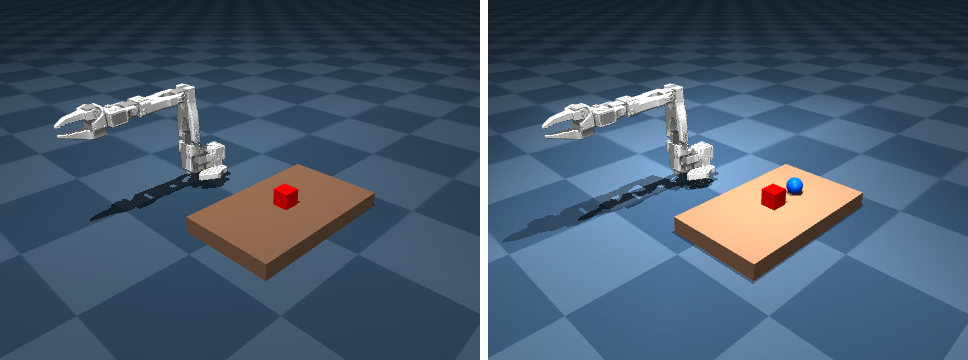

In [6]:
turn("add a blue ball and a light", "t2_ball_and_light")

## Turn 3: a camera looking at the arm

> put a camera looking at the arm

  sim_world.camera({"name": "arm_cam", "position": [0.55, -0.55, 0.45], "target": [0.0, -0.15, 0.15], "fov": 50})  -> ok
  sim_world.render({"camera": "arm_cam"})  -> ok

I added a camera named `arm_cam` aimed at the arm. In the test render the whole arm is in view, with the table, red cube and blue ball in the lower right corner.

- **Placement:** it sits at (0.55, -0.55, 0.45) m, in front of and to the side of the arm, and points at the middle of the arm, around (0, -0.15, 0.15) m.
- **Image:** 640×480 with a 50° field of view.

The arm is still stretched out and pointing away from the table, as before.



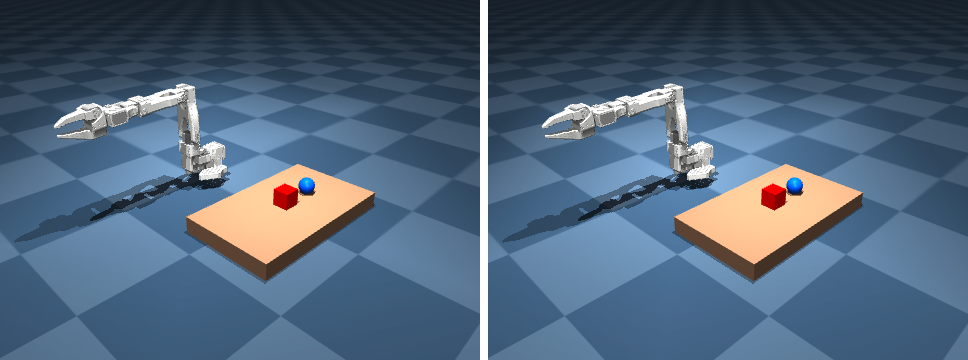

In [7]:
turn("put a camera looking at the arm", "t3_camera")

## Turn 4: the agent looks through its camera

`render` returns the picture as an image block, so the model sees it. Below is the exact image it was sent.

  sim_world.render({"camera": "arm_cam"})  -> ok

From `arm_cam`, the white arm stands upright with its open gripper stretched sideways away from the table, and the red cube and blue ball sit side by side on the lit tabletop in the lower right corner.



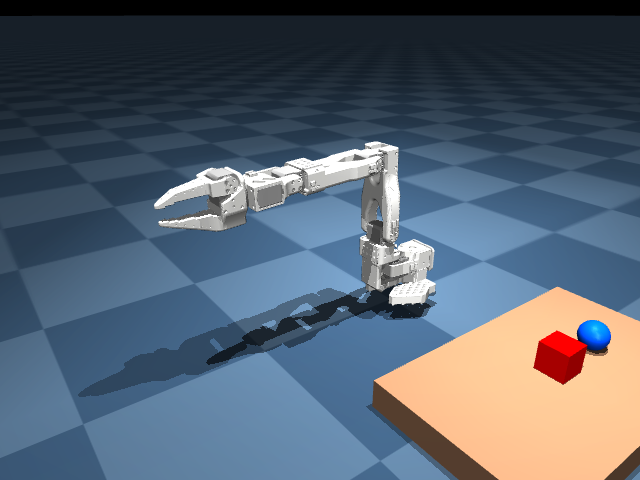

In [8]:
reply = agent("render the camera you added and tell me in one sentence what you see")
new_calls()
print(f"\n{str(reply).strip()}")
seen = [
    c["image"]["source"]["bytes"]
    for m in agent.messages for b in m["content"] if "toolResult" in b
    for c in b["toolResult"]["content"] if "image" in c
]
saw = np.asarray(Image.open(io.BytesIO(seen[-1])).convert("RGB"))
Image.fromarray(saw).save(MEDIA / "t4_what_the_agent_saw.png")
_nb.show(_nb.image(saw, width=480))

## The world it built

`describe()` is what the agent reads too.

In [9]:
world = sim.describe()
for o in world["objects"]:
    print(f"{o['name']:10s} {o['shape']:8s} at {np.round(o['position'], 3).tolist()}")
print("cameras:", [c["name"] for c in world["cameras"]])

table      box      at [0.3, 0.0, 0.02]
red_cube   box      at [0.3, -0.0, 0.06]
blue_ball  sphere   at [0.3, 0.08, 0.06]
cameras: ['hero', 'overview', 'arm_cam']


An orbit around it. `camera()` with a name that exists re-aims that camera in place.

In [10]:
frames = []
for i in range(36):
    a = 2 * np.pi * i / 36
    sim.camera("orbit", position=(0.15 + 0.75 * np.cos(a), 0.75 * np.sin(a), 0.5), target=(0.15, 0.0, 0.05), size=(400, 300))
    frames.append(sim.render("orbit"))
_nb.gif(frames, "03/orbit.gif", width=400, fps=12)

media/03/orbit.gif: 36 frames, 1.45 MB


PosixPath('/Users/cagatay/robots-test-cagatay/notebooks/media/03/orbit.gif')

![orbit of the world the agent built](media/03/orbit.gif)

## Your turn

The same agent in a loop. In a terminal: `python notebooks/scripts/03_agent_builds_a_world.py --repl`.

In [11]:
if "--repl" in sys.argv:
    while True:
        print(agent(input("> ")))

In [12]:
sim.close()